Dataset: Breast Cancer
Number of samples: 569
Number of features: 30

Actual Labels:
[0 1 0 1 0 1 1 0 0 0 1 0 1 0 0 1 1 1 1 1 0 0 1 1 1 1 0 1 1 1 1 1 1 1 0 0 1
 1 1 0 1 1 1 0 0 1 1 1 1 0 1 1 1 0 1 1 1 0 0 1 1 1 1 1 0 0 1 1 1 1 1 1 1 0
 0 0 0 1 1 1 1 1 0 1 0 1 1 1 1 1 1 1 0 0 0 1 0 1 0 1 0 0 0 1 0 0 1 0 1 0 1
 0 1 1]

Predicted Labels:
[0 1 0 1 0 1 1 0 0 0 1 0 1 0 0 1 0 1 1 1 0 0 1 1 1 1 0 1 1 1 1 1 1 1 0 0 1
 1 1 0 1 1 1 0 0 1 1 1 1 0 1 1 1 1 1 1 1 0 0 1 1 1 1 1 0 0 1 1 1 1 1 1 1 0
 0 0 0 1 1 1 1 1 0 1 0 1 1 1 1 1 1 1 0 0 0 1 0 1 0 1 0 0 0 1 0 0 1 0 1 0 1
 0 1 1]

Accuracy: 98.25 %

Confusion Matrix:
[[41  1]
 [ 1 71]]


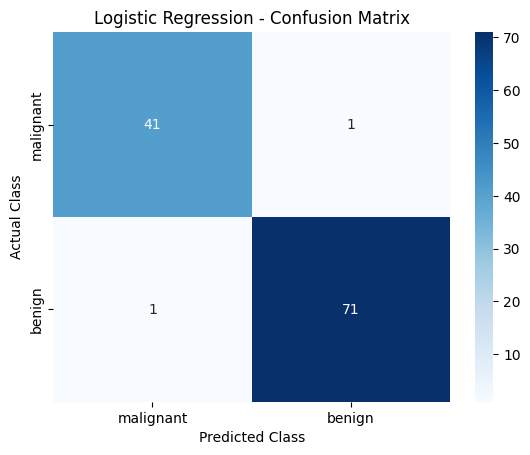


Classification Report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

Sample Predicted Class: malignant

Logistic Regression completed successfully.


In [7]:

# Implementation of Logistic Regression Algorithm

# Step 1: Import required libraries
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.metrics import classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Step 2: Load the dataset
data = load_breast_cancer()
X = data.data
y = data.target

print("Dataset: Breast Cancer")
print("Number of samples:", X.shape[0])
print("Number of features:", X.shape[1])

# Step 3: Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Step 4: Standardize the features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Step 5: Create and train the Logistic Regression model
model = LogisticRegression(max_iter=5000)
model.fit(X_train, y_train)

# Step 6: Predict the test data
y_pred = model.predict(X_test)

print("\nActual Labels:")
print(y_test)

print("\nPredicted Labels:")
print(y_pred)

# Step 7: Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print("\nAccuracy:", round(accuracy * 100, 2), "%")

# Step 8: Display confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=data.target_names,
    yticklabels=data.target_names
)
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

# Step 9: Display classification report
print("\nClassification Report:")
print(classification_report(
    y_test, y_pred, target_names=data.target_names
))

# Step 10: Predict a sample
sample = X_test[0].reshape(1, -1)
prediction = model.predict(sample)

print("Sample Predicted Class:",
      data.target_names[prediction[0]])
print("\nLogistic Regression completed successfully.")
